In [4]:
from statsmodels.tsa.api import Holt
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from tqdm import tqdm

In [5]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\monthly-milk-production-pounds-p.csv")
y=df.Milk
y_train,y_test=df.Milk[:-12],df.Milk[-12:]

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\anaconda3\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


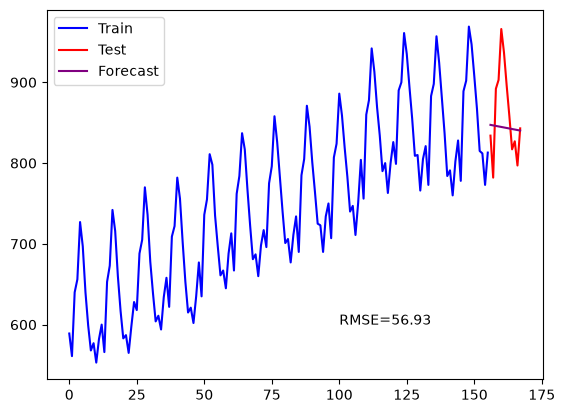

In [6]:
alpha , beta=  0.1, 0.2
holt = Holt(y_train)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend= beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\anaconda3\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


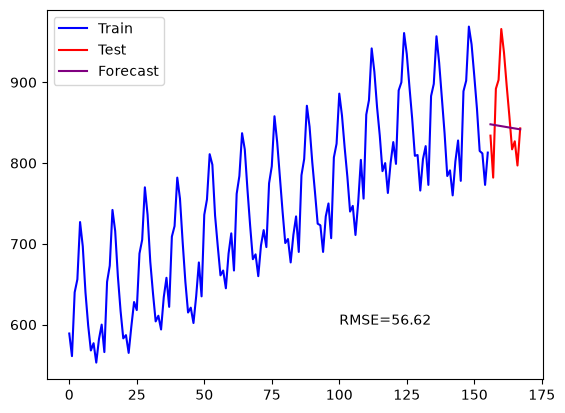

In [7]:
alpha , beta=  0.1, 0.2
holt = Holt(y_train, exponential = True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend= beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

Holt's Additive

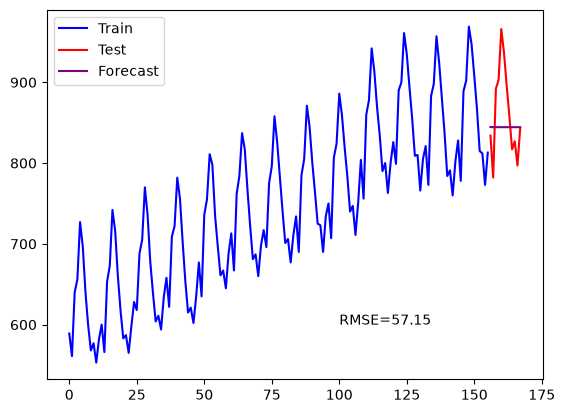

In [11]:
alpha , beta, phi=  0.1, 0.2, 0.3
holt = Holt(y_train, damped_trend= True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend= beta,optimized=False,damping_trend=phi)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

Holt's Multiplicative

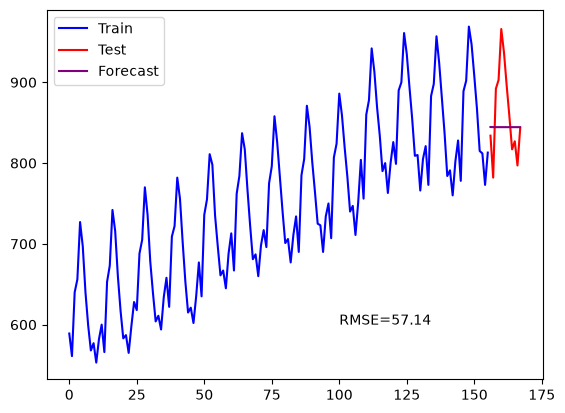

In [12]:
alpha , beta, phi=  0.1, 0.2, 0.3
holt = Holt(y_train, damped_trend= True, exponential= True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend= beta,optimized=False,damping_trend=phi)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

In [7]:
from statsmodels.tsa.api import ExponentialSmoothing

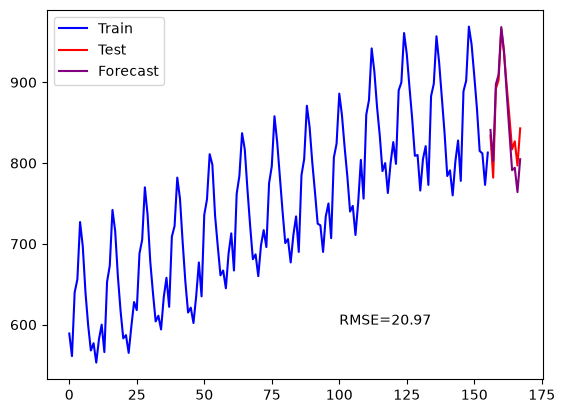

In [18]:
alpha , beta, gamma =  0.6, 0.2, 0.1
hw_add = ExponentialSmoothing(y_train, seasonal_periods= 12, trend = 'add', seasonal= 'add')
fit1 = hw_add.fit(smoothing_level = alpha, smoothing_trend= beta,optimized=False,smoothing_seasonal=gamma)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

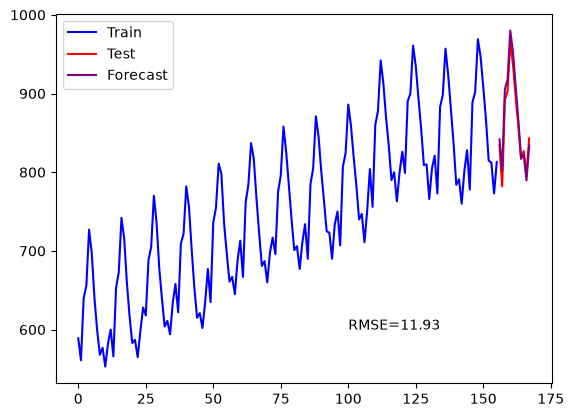

In [22]:

hw_add = ExponentialSmoothing(y_train, seasonal_periods= 12, trend = 'add', seasonal= 'add')
fit1 = hw_add.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(100,600,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

In [9]:
alpha , beta, gamma =  np.linspace(0.01,0.99,10), np.linspace(0.01,0.99,10), np.linspace(0.01,0.99,10)
scores = []
for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            hw_add = ExponentialSmoothing(y_train, seasonal_periods= 12, trend = 'add', seasonal= 'add')
            fit1 = hw_add.fit(smoothing_level = a, smoothing_trend= b,optimized=False,smoothing_seasonal=g)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,g, root_mean_squared_error(y_test, fcast1)])
df_scores = pd.DataFrame(scores, columns= ['alpha', 'beta','gamma','score'])
df_scores.sort_values('score')

100%|██████████| 10/10 [00:07<00:00,  1.37it/s]


,alpha,beta,gamma,score
608,0.663333,0.010000,0.881111,8.990331
507,0.554444,0.010000,0.772222,9.373216
607,0.663333,0.010000,0.772222,9.541263
708,0.772222,0.010000,0.881111,10.397679
506,0.554444,0.010000,0.663333,10.421352
...,...,...,...,...
899,0.881111,0.990000,0.990000,90653.169465
988,0.990000,0.881111,0.881111,93715.538810
989,0.990000,0.881111,0.990000,170080.243023
998,0.990000,0.990000,0.881111,296360.294623
